# 04 — Analyse statistique

**Objectif** : tester formellement les hypothèses formulées dans le notebook `03`.

Chaque test est précédé de son hypothèse nulle. Le seuil retenu est α = 0,05.

In [ ]:
import importlib
import sys
from pathlib import Path

racine = Path.cwd().resolve()
if not (racine / "src").is_dir():
    racine = racine.parent
sys.path.insert(0, str(racine))

import src

importlib.reload(src)


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats

from src import FIGURES_DIR, VENTES_PROPRES_CSV

sns.set_theme(style="whitegrid")
ALPHA = 0.05

In [2]:
df = pd.read_csv(
    VENTES_PROPRES_CSV,
    parse_dates=["periode"],
    dtype={"id_region": str, "code_plage_prix": str, "code_nature_acte": str},
)

serie = (
    df.groupby("periode", as_index=False)["nombre_ventes"]
    .sum()
    .sort_values("periode")
    .reset_index(drop=True)
)
serie["annee"] = serie["periode"].dt.year
serie["mois"] = serie["periode"].dt.month
serie.head()

,periode,nombre_ventes,annee,mois
0,2021-01-01,12685,2021,1
1,2021-02-01,16017,2021,2
2,2021-03-01,19979,2021,3
3,2021-04-01,23136,2021,4
4,2021-05-01,26091,2021,5


## 1. Normalité du volume mensuel

**H₀** : le volume mensuel québécois suit une loi normale.

In [3]:
valeurs = serie["nombre_ventes"].dropna()
stat_sw, p_sw = stats.shapiro(valeurs)

print(f"Shapiro-Wilk : W = {stat_sw:.4f}, p = {p_sw:.4g}")
print(f"Asymétrie : {stats.skew(valeurs):.3f} | Aplatissement : {stats.kurtosis(valeurs):.3f}")
print(
    "→ Distribution non normale : privilégier les tests non paramétriques."
    if p_sw < ALPHA
    else "→ Normalité non rejetée."
)

Shapiro-Wilk : W = 0.9192, p = 0.0002988
Asymétrie : 1.283 | Aplatissement : 2.629
→ Distribution non normale : privilégier les tests non paramétriques.


## 2. Effet de la saison

**H₀** : le volume d'avril à septembre est identique à celui d'octobre à mars.

In [4]:
haute = serie.loc[serie["mois"].between(4, 9), "nombre_ventes"]
basse = serie.loc[~serie["mois"].between(4, 9), "nombre_ventes"]

stat_mw, p_mw = stats.mannwhitneyu(haute, basse, alternative="two-sided")

print(f"Médiane haute saison : {haute.median():,.0f}")
print(f"Médiane basse saison : {basse.median():,.0f}")
print(f"Mann-Whitney : U = {stat_mw:.0f}, p = {p_mw:.4g}")
print(
    "→ Écart saisonnier statistiquement significatif."
    if p_mw < ALPHA
    else "→ Aucun écart saisonnier détectable."
)

Médiane haute saison : 17,045
Médiane basse saison : 12,685
Mann-Whitney : U = 927, p = 1.848e-05
→ Écart saisonnier statistiquement significatif.


## 3. Différence entre les plages de prix

**H₀** : les trois plages présentent la même distribution de volumes mensuels
à l'échelle du Québec.

In [5]:
mensuel_plage = df.groupby(["periode", "plage_prix"], as_index=False)["nombre_ventes"].sum()
groupes = [
    g["nombre_ventes"].to_numpy()
    for _, g in mensuel_plage.groupby("plage_prix")
]
stat_kw, p_kw = stats.kruskal(*groupes)

print(f"Kruskal-Wallis : H = {stat_kw:.2f}, p = {p_kw:.4g}")
print(
    "→ Les plages de prix ne sont pas équivalentes."
    if p_kw < ALPHA
    else "→ Pas de différence détectable entre les plages."
)

Kruskal-Wallis : H = 23.99, p = 6.164e-06
→ Les plages de prix ne sont pas équivalentes.


## 4. Tendance temporelle

**H₀** : aucune tendance monotone du volume québécois.

In [6]:
serie["t"] = np.arange(len(serie))

rho, p_rho = stats.spearmanr(serie["t"], serie["nombre_ventes"])
print(f"Spearman : rho = {rho:.3f}, p = {p_rho:.4g}")

modele = sm.OLS(serie["nombre_ventes"], sm.add_constant(serie[["t"]])).fit()
print(modele.summary())

Spearman : rho = -0.297, p = 0.01407
                            OLS Regression Results                            
Dep. Variable:          nombre_ventes   R-squared:                       0.105
Model:                            OLS   Adj. R-squared:                  0.092
Method:                 Least Squares   F-statistic:                     7.763
Date:                Sat, 26 Sep 2026   Prob (F-statistic):            0.00695
Time:                        17:05:14   Log-Likelihood:                -676.03
No. Observations:                  68   AIC:                             1356.
Df Residuals:                      66   BIC:                             1360.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.8

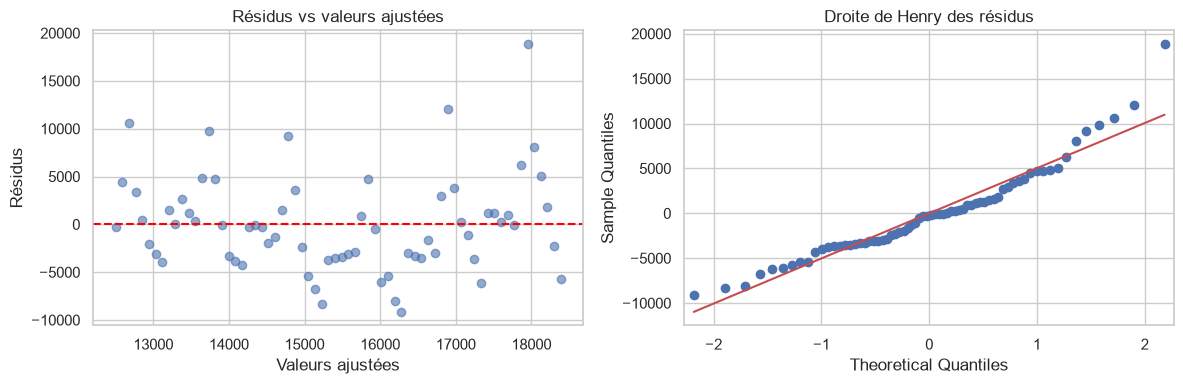

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(modele.fittedvalues, modele.resid, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Résidus vs valeurs ajustées")
axes[0].set_xlabel("Valeurs ajustées")
axes[0].set_ylabel("Résidus")
sm.qqplot(modele.resid, line="s", ax=axes[1])
axes[1].set_title("Droite de Henry des résidus")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_diagnostic_residus.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Corrélations entre plages de prix

Des plages fortement corrélées réagissent au même facteur macroéconomique.

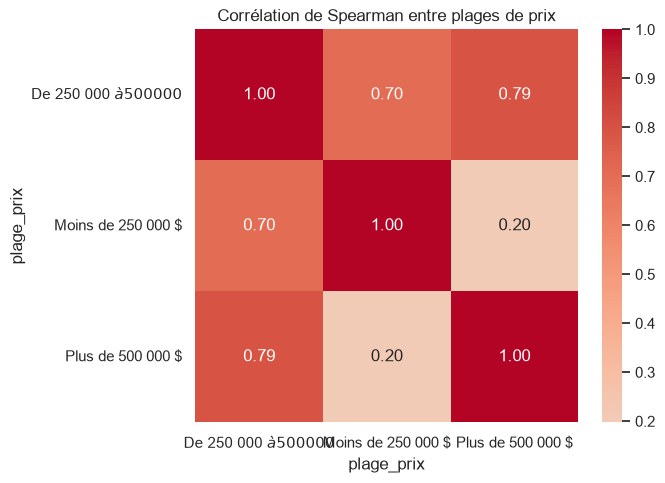

In [8]:
pivot = mensuel_plage.pivot(index="periode", columns="plage_prix", values="nombre_ventes")

plt.figure(figsize=(7, 5))
sns.heatmap(pivot.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélation de Spearman entre plages de prix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_correlations_plages.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

Seuil α = 0,05. Si p < 0,05, on **rejette** l’hypothèse nulle.

| Hypothèse nulle | Test | p-valeur | Décision |
| --- | --- | --- | --- |
| Le volume mensuel est normal | Shapiro-Wilk | 0,0003 | **Rejetée** : distribution non normale |
| Avril–septembre = octobre–mars | Mann-Whitney | 0,000018 | **Rejetée** : haute saison plus forte (médianes 17 045 vs 12 685) |
| Les 3 plages ont le même volume | Kruskal-Wallis | 0,000006 | **Rejetée** : les plages ne sont pas équivalentes |
| Aucune tendance dans le temps | Spearman / OLS | 0,014 / 0,007 | **Rejetée** : tendance **baissière** (ρ = −0,30 ; environ −88 ventes/mois) |

**Ce que ça change pour la suite**

- On garde des tests **non paramétriques** (Shapiro l’impose).
- Le notebook `05` doit coder la **saison** (sinus/cosinus du mois) et des **retards**, parce que le volume d’hier et le mois de l’année prédisent mieux qu’une simple droite.
- La tendance OLS n’explique que **10 %** de la variance (R² = 0,11) et les résidus restent saisonniers (Durbin-Watson = 0,72) : une droite seule est insuffisante.
- Les plages n’ayant pas le même volume, on les garde comme **séries distinctes** (région × plage), pas comme un seul total québécois.